# Tech Challenge Fase 2 — Demonstração

**Projeto 1: Otimização de Modelos de Diagnóstico**

Este notebook percorre todo o fluxo da solução:

1. **Base da Fase 1** — dados e baselines
2. **Algoritmo Genético** — otimização de hiperparâmetros
3. **Experimentos** — 4 configurações por modelo
4. **Comparativo** — otimizado × original no holdout
5. **Integração com LLM** — explicações em linguagem natural

> Use o kernel do venv do projeto (Python 3.13).

## 0. Setup

In [20]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))  # raiz do projeto

import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data import get_split
print('Setup OK')
print('pandas', pd.__version__, '| numpy', np.__version__)

Setup OK
pandas 3.0.3 | numpy 2.4.6


## 1. Base da Fase 1 — dados e baselines

Dataset Breast Cancer Wisconsin (Diagnostic): 569 amostras, 30 features, 2 classes.

In [21]:
X_train, X_test, y_train, y_test = get_split()
print(f'Treino: {X_train.shape} | Teste: {X_test.shape}')
print('Distribuição do alvo (treino):')
print(y_train.value_counts().sort_index())

Treino: (455, 30) | Teste: (114, 30)
Distribuição do alvo (treino):
target
0    170
1    285
Name: count, dtype: int64


In [22]:
# Baselines da Fase 1 (GridSearchCV)
from src.models.base_models import train_baselines

baseline = train_baselines()
baseline['results'][['model', 'accuracy', 'precision', 'recall', 'f1', 'best_cv_accuracy']]

,model,accuracy,precision,recall,f1,best_cv_accuracy
0,svc,0.982456,0.986111,0.986111,0.986111,0.973626
1,logreg,0.973684,0.972603,0.986111,0.979310,0.982418
2,rf,0.956140,0.958904,0.972222,0.965517,0.962637


## 2. Algoritmo Genético

Cada cromossomo é um vetor de genes normalizados em [0, 1]; a função `decode_genes` converte para os hiperparâmetros do scikit-learn. A fitness é a accuracy média com **validação cruzada estratificada 5-fold**.

In [23]:
from src.models.search_space import decode_genes, n_genes, ALL_MODELS

# Exemplo de decodificação
for m in ALL_MODELS:
    genes = [0.3, 0.7, 0.5][:n_genes(m)]  # garante tamanho compatível com o modelo
    print(f'{m} ({n_genes(m)} genes):', decode_genes(m, genes))

logreg (2 genes): {'C': 0.00630957344480193, 'class_weight': 'balanced'}
rf (3 genes): {'n_estimators': 74, 'max_depth': 22, 'min_samples_split': 11}
svc (3 genes): {'C': 0.0630957344480193, 'gamma': 0.31622776601683794, 'kernel': 'linear'}


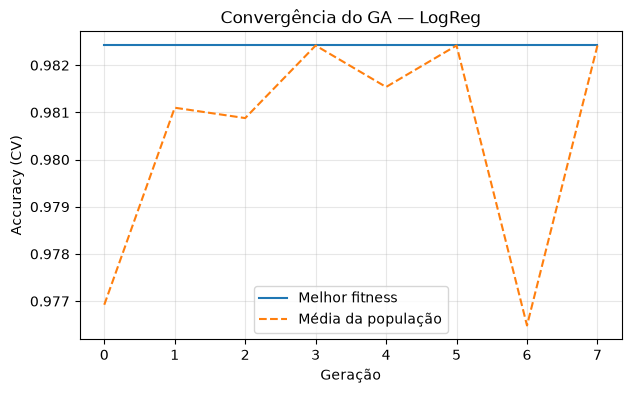

Melhor fitness: 0.9824
Melhores parâmetros: {'C': 0.21257330366628913, 'class_weight': None}


In [24]:
# Execução curta do GA para LogReg (demonstração)
from src.ga.config import GAConfig
from src.ga.genetic_algorithm import run_ga

cfg = GAConfig(population_size=10, generations=8, mutation_rate=0.1, random_state=42)
res = run_ga('logreg', X_train, y_train, cfg)

plt.figure(figsize=(7, 4))
plt.plot(res.history, label='Melhor fitness')
plt.plot(res.mean_history, '--', label='Média da população')
plt.xlabel('Geração'); plt.ylabel('Accuracy (CV)')
plt.title('Convergência do GA — LogReg')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

print('Melhor fitness:', round(res.best_fitness, 4))
print('Melhores parâmetros:', res.best_params)

## 3. Experimentos (4 configurações × 3 modelos)

Resultados consolidados da execução da matriz de experimentos (12 execuções no total).

In [25]:
import os
exp_path = '../results/metrics/experiments_summary.csv'
if os.path.exists(exp_path):
    exp = pd.read_csv(exp_path)
    display(exp[['model', 'experiment', 'population_size', 'generations', 'mutation_rate', 'selection', 'best_fitness', 'baseline_cv_accuracy']])  # garante a renderização
else:
    print('Arquivo de experimentos não encontrado. Rode run_experiments.py antes.')

,model,experiment,population_size,generations,mutation_rate,selection,best_fitness,baseline_cv_accuracy
0,rf,exp1,5,8,0.10,tournament,0.960440,0.962637
1,rf,exp2,8,8,0.10,tournament,0.962637,0.962637
2,rf,exp3,5,10,0.30,roulette,0.964835,0.962637
3,rf,exp4,8,10,0.15,tournament,0.967033,0.962637
4,logreg,exp1,10,15,0.10,tournament,0.982418,0.982418
5,logreg,exp2,16,15,0.10,tournament,0.984615,0.982418
6,logreg,exp3,10,20,0.30,roulette,0.984615,0.982418
7,logreg,exp4,16,20,0.15,tournament,0.984615,0.982418
8,svc,exp1,10,15,0.10,tournament,0.962637,0.973626
9,svc,exp2,16,15,0.10,tournament,0.980220,0.973626


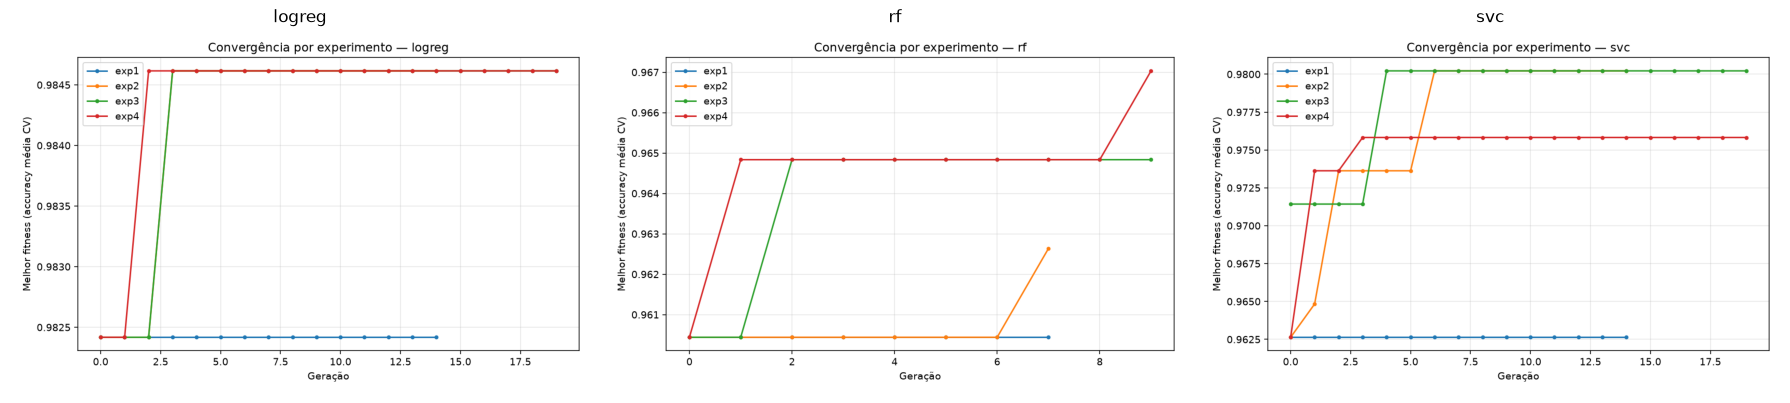

In [26]:
# Curvas de convergência por modelo (se já geradas)
import glob
figs = sorted(glob.glob('../results/figures/experiments_*.png'))
if figs:
    fig, axes = plt.subplots(1, len(figs), figsize=(6 * len(figs), 4))
    if len(figs) == 1:
        axes = [axes]
    for ax, f in zip(axes, figs):
        img = plt.imread(f)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(os.path.basename(f).replace('experiments_', '').replace('.png', ''))
    plt.tight_layout(); plt.show()
else:
    print('Figuras de convergência não encontradas.')

## 4. Comparativo: otimizado × original no holdout

In [27]:
comp_path = '../results/metrics/comparativo_original_vs_ga.csv'
if os.path.exists(comp_path):
    comp = pd.read_csv(comp_path)
    display(comp)  # garante a renderização da tabela
else:
    print('Arquivo de comparativo não encontrado. Rode compare_models.py antes.')

,model,version,source,accuracy,precision,recall,f1
0,logreg,baseline (GridSearch),Fase 1,0.973684,0.972603,0.986111,0.979310
1,logreg,GA-exp1,"GA (10 pop, 15 gen, mut 0.1)",0.982456,0.986111,0.986111,0.986111
2,logreg,GA-exp2,"GA (16 pop, 15 gen, mut 0.1)",0.982456,0.986111,0.986111,0.986111
3,logreg,GA-exp3,"GA (10 pop, 20 gen, mut 0.3)",0.982456,0.986111,0.986111,0.986111
4,logreg,GA-exp4,"GA (16 pop, 20 gen, mut 0.15)",0.973684,0.972603,0.986111,0.979310
5,rf,baseline (GridSearch),Fase 1,0.956140,0.958904,0.972222,0.965517
6,rf,GA-exp1,"GA (5 pop, 8 gen, mut 0.1)",0.947368,0.958333,0.958333,0.958333
7,rf,GA-exp2,"GA (8 pop, 8 gen, mut 0.1)",0.956140,0.958904,0.972222,0.965517
8,rf,GA-exp3,"GA (5 pop, 10 gen, mut 0.3)",0.956140,0.958904,0.972222,0.965517
9,rf,GA-exp4,"GA (8 pop, 10 gen, mut 0.15)",0.956140,0.958904,0.972222,0.965517


## 5. Integração com LLM

Usa **Ollama local + llama3.2 (3B)** para gerar explicações em linguagem natural. Requer o servidor Ollama rodando (`ollama serve`) com o modelo baixado (`ollama pull llama3.2`).

A **primeira análise** usa a **imagem mais sugestiva** do holdout — o exame com maior probabilidade de malignidade prevista pelo modelo. Em seguida, fazemos a **verificação aleatória de mais 1 imagem** (com semente fixa para reprodutibilidade), demonstrando que a LLM também explica diagnósticos em casos **não** escolhidos manualmente.

In [28]:
from src.llm.interpreter import OllamaClient, interpret_case, translate_feature_name
import joblib

client = OllamaClient()
disponivel = client.is_available()
print('Ollama disponível:', disponivel)

TOP_FEATURES = ['worst area', 'worst texture', 'worst concave points']


def explicar_caso(pipe, Xt, pos, rotulo):
    """Gera e imprime a explicação da LLM para um exame específico do holdout."""
    row = Xt.iloc[pos]
    proba_maligna = float(pipe.predict_proba(Xt.iloc[[pos]])[:, 1][0])
    pred = int(pipe.predict(Xt.iloc[[pos]])[0])
    top = [(n, float(row[n])) for n in TOP_FEATURES]

    explicacao = interpret_case(
        client,
        model_name='Regressão Logística otimizada por GA',
        prediction=pred,
        proba_maligna=proba_maligna,
        top_features=top,
    )
    print(f'\n=== {rotulo} ===')
    print(f'Exame #{pos} | Prob. malignidade: {proba_maligna*100:.1f}% | '
          f'Classificação: {"MALIGNO" if pred == 1 else "BENIGNO"}')
    print('Principais características: ' + '; '.join(
        f'{translate_feature_name(n)} = {v:.3f}' for n, v in top))
    print('--- Explicação gerada pela LLM ---')
    print(explicacao)


if disponivel:
    pipe = joblib.load('../models/ga_best_logreg.joblib')
    Xt = X_test.reset_index(drop=True)
    proba = pipe.predict_proba(Xt)[:, 1]

    # 1) Imagem mais sugestiva (maior probabilidade de malignidade no holdout)
    pos_sugestivo = int(np.argmax(proba))
    explicar_caso(pipe, Xt, pos_sugestivo, 'Exame 1 — imagem mais sugestiva')

    # 2) Verificação aleatória de mais 1 imagem (semente fixa p/ reprodutibilidade)
    candidatos = [i for i in range(len(Xt)) if i != pos_sugestivo]
    pos_aleatorio = int(np.random.default_rng(42).choice(candidatos, size=1)[0])
    explicar_caso(pipe, Xt, pos_aleatorio, 'Exame 2 — verificação aleatória')
else:
    print('Inicie o Ollama e rode: ollama pull llama3.2')

Ollama disponível: True

=== Exame 1 — imagem mais sugestiva ===
Exame #95 | Prob. malignidade: 100.0% | Classificação: MALIGNO
Principais características: pior área = 392.200; pior textura = 14.820; pior pontos côncavos = 0.032
--- Explicação gerada pela LLM ---
Com base nos resultados do modelo de classificação, podemos concluir que há um alto nível de risco de malignidade no tumor de mama observado. A probabilidade de malignidade é de 100.0%, o que indica que o modelo está confiante na classificação como maligno. 

Os principais fatores que influenciaram essa decisão incluem a pior área (392.200), pior textura (14.820) e pior pontos côncavos (0.032), que são características comuns usadas para avaliar a complexidade e a heterogeneidade dos tumores de mama. 

É importante notar que, embora o modelo esteja confiante na classificação, é fundamental que um profissional de saúde avalie e confirme os resultados por meio de exames adicionais e avaliações clínicas. O modelo é uma ferramenta 

## Conclusão

- O **AG** otimizou os hiperparâmetros dos modelos da Fase 1, melhorando o **LogReg em +0.88 pp no holdout** (0.9825 vs 0.9737) e explorando regiões fora do grid original (SVC com `kernel=linear`).
- A **LLM local** gerou explicações claras e fieis (scores de qualidade 1.0), com disclaimer e sem alucinação.
- Projeto **testado** (34 testes, 82% de cobertura), **monitorado** (logs + tracking) e **documentado** (`reports/relatorio_fase2.md`).